In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("../01 - DataPreparation/df_prepared.csv")

In [3]:
feature_cols = ['MinPlayers', 'MaxPlayers_log', 'Rating',
       'IsReimplementation', 'Kickstarted', 'Cat:Thematic', 'Cat:Strategy',
       'Cat:War', 'Cat:Family', 'Cat:CGS', 'Cat:Abstract', 'Cat:Party',
       'Cat:Childrens', 'Age', 'AgeRec', 'NumOwned_log', 'NumAlternates_log',
       'NumExpansions_log', 'NumImplementations_log', 'NumWant_log', 'AvgPlaytime_log']

In [4]:
X = df[feature_cols].copy()
y = df['GameWeight'].copy()

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [6]:
preprocess = ColumnTransformer(
    transformers=[("rating", OneHotEncoder(handle_unknown="ignore"), ["Rating"])],
    remainder="passthrough"
)

model = Pipeline(steps=[
    ("prep", preprocess),
    ("scale", StandardScaler(with_mean=False)),
    ("knn", KNeighborsRegressor())
])


In [7]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f"Baseline MAE:  {mae:.3f}")
print(f"Baseline RMSE: {rmse:.3f}")
print(f"Baseline R²:   {r2:.3f}")

Baseline MAE:  0.347
Baseline RMSE: 0.457
Baseline R²:   0.671


Base KNN Regressor performs strongly for GameWeight: MAE = 0.347, RMSE = 0.457, and R² = 0.671, meaning it explains about 67% of the variance with relatively low prediction error.

In [8]:
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
    "knn__leaf_size": [20, 30, 40]
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    model,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)

grid.fit(X_train, y_train)
best_model = grid.best_estimator_

print("\nBest params:", grid.best_params_)
print("Best CV MAE:", round(-grid.best_score_, 3))


Best params: {'knn__leaf_size': 20, 'knn__n_neighbors': 15, 'knn__p': 1, 'knn__weights': 'distance'}
Best CV MAE: 0.335


Tuning selects a KNN regressor with 15 neighbors, Manhattan distance (p=1), and distance weighting (closer points matter more), reaching a best CV MAE of 0.335, which is a small improvement over the baseline error.

In [13]:
y_pred = best_model.predict(X_test)

train_mae = round(-grid.best_score_, 3)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nTrain MAE:", train_mae)
print(f"Test MAE:  {mae:.3f}")
print(f"Test RMSE: {rmse:.3f}")
print(f"Test R²:   {r2:.3f}")


Train MAE: 0.335
Test MAE:  0.333
Test RMSE: 0.434
Test R²:   0.702


Using CV-based train MAE (0.335), the tuned KNN generalizes very well: test MAE (0.333) is essentially identical (gap ≈ -0.002), indicating no overfitting; overall test performance is strong (RMSE=0.434, R²=0.702).

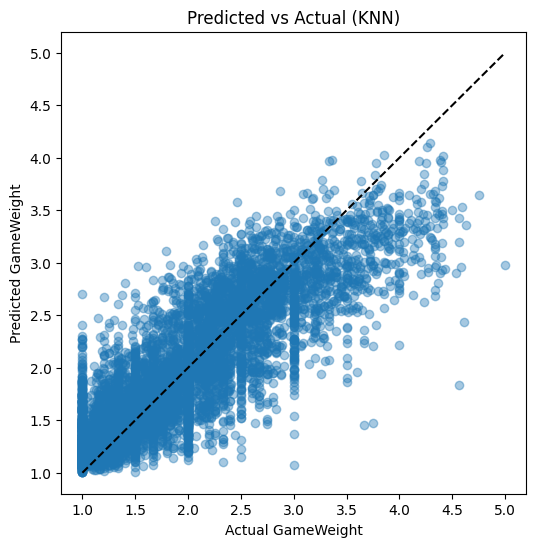

In [10]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.4)
mn = min(y_test.min(), y_pred.min())
mx = max(y_test.max(), y_pred.max())
plt.plot([mn, mx], [mn, mx], "k--")
plt.xlabel("Actual GameWeight")
plt.ylabel("Predicted GameWeight")
plt.title("Predicted vs Actual (KNN)")
plt.show()

Clear positive trend with many points near the diagonal, but predictions are slightly “shrunk” toward the mean (underestimates at high GameWeight, overestimates at low values).

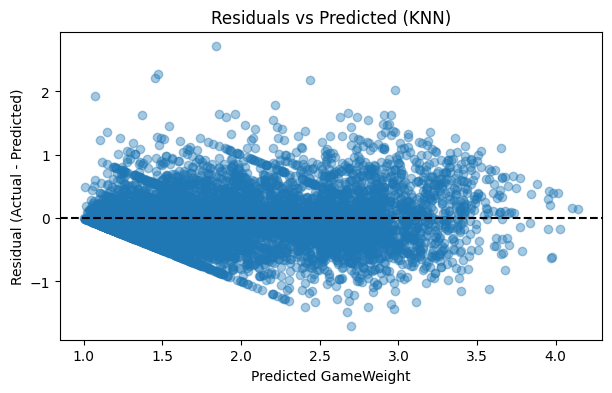

In [11]:
residuals = y_test - y_pred
plt.figure(figsize=(7,4))
plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(0, linestyle="--", color="k")
plt.xlabel("Predicted GameWeight")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals vs Predicted (KNN)")
plt.show()